In [1]:
import torch

print(torch.__version__)
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

2.11.0+cu128
True
NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [2]:
from ultralytics import YOLO

# Load the model
model = YOLO("yolov8s.pt")

# Train the model
model.train(
    data="../dataset_yolo/dataset.yaml",
    epochs=30,
    imgsz=640,
    project="../results",
    name="train"
)

New https://pypi.org/project/ultralytics/8.4.92 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.91  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../dataset_yolo/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  4,  5,  6,  7,  8,  9, 10, 11, 12, 14, 16, 17, 18, 19, 20, 21, 23, 27, 29, 30, 31, 32, 33, 34, 36, 37, 39, 40, 42, 44, 45, 46, 47, 48, 49, 50, 51, 54, 55, 57, 58, 59])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001E403C54A90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    

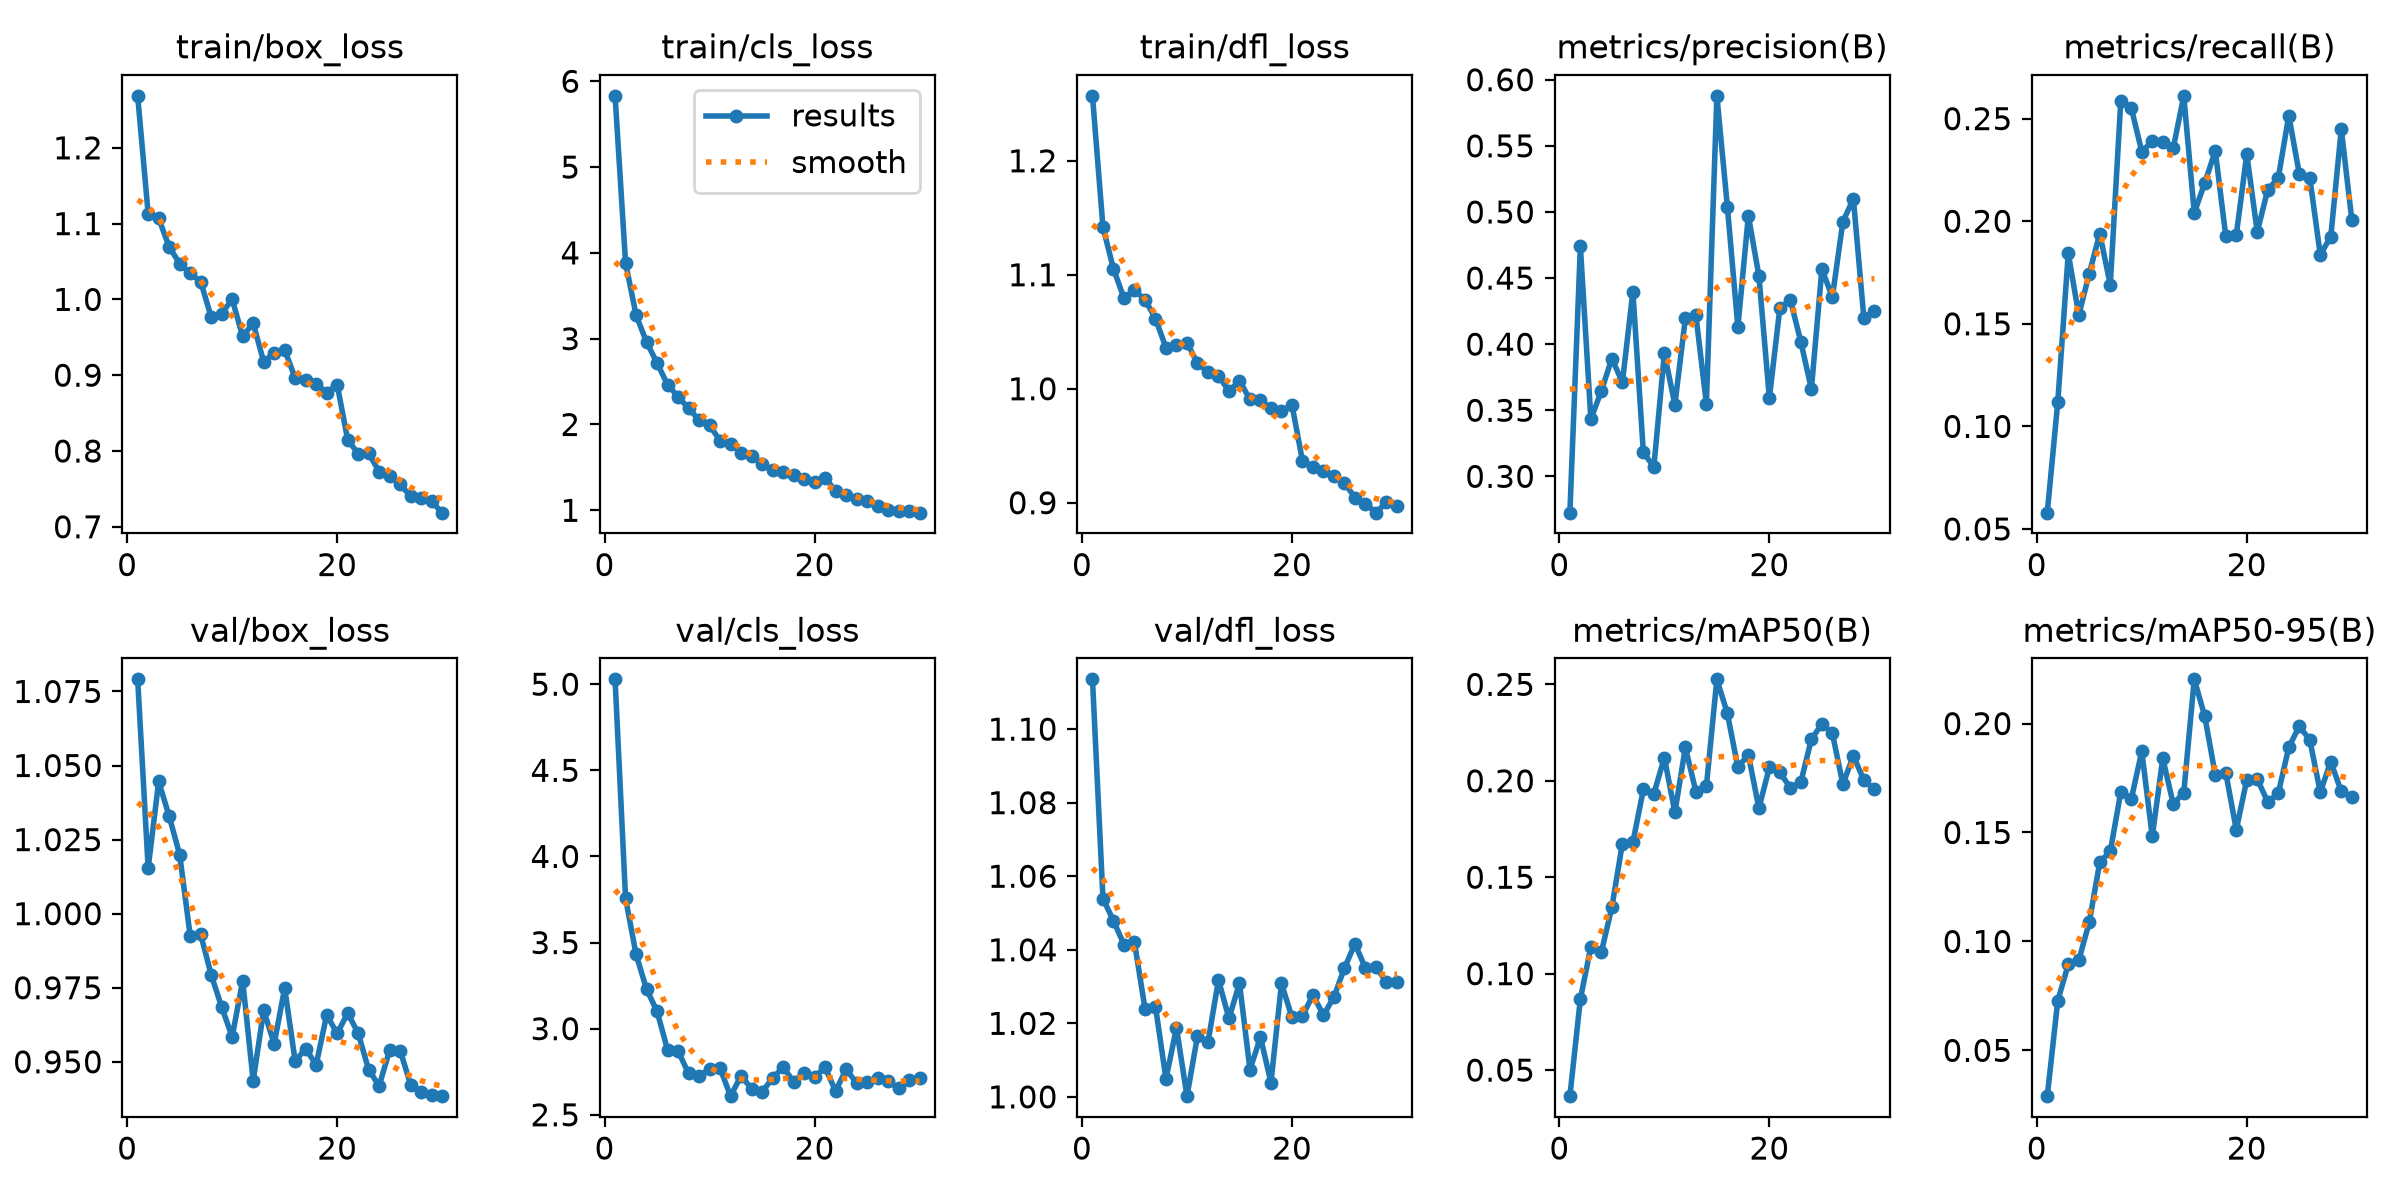

In [5]:
from IPython.display import Image

Image(r"../runs/results/train-3/results.png")

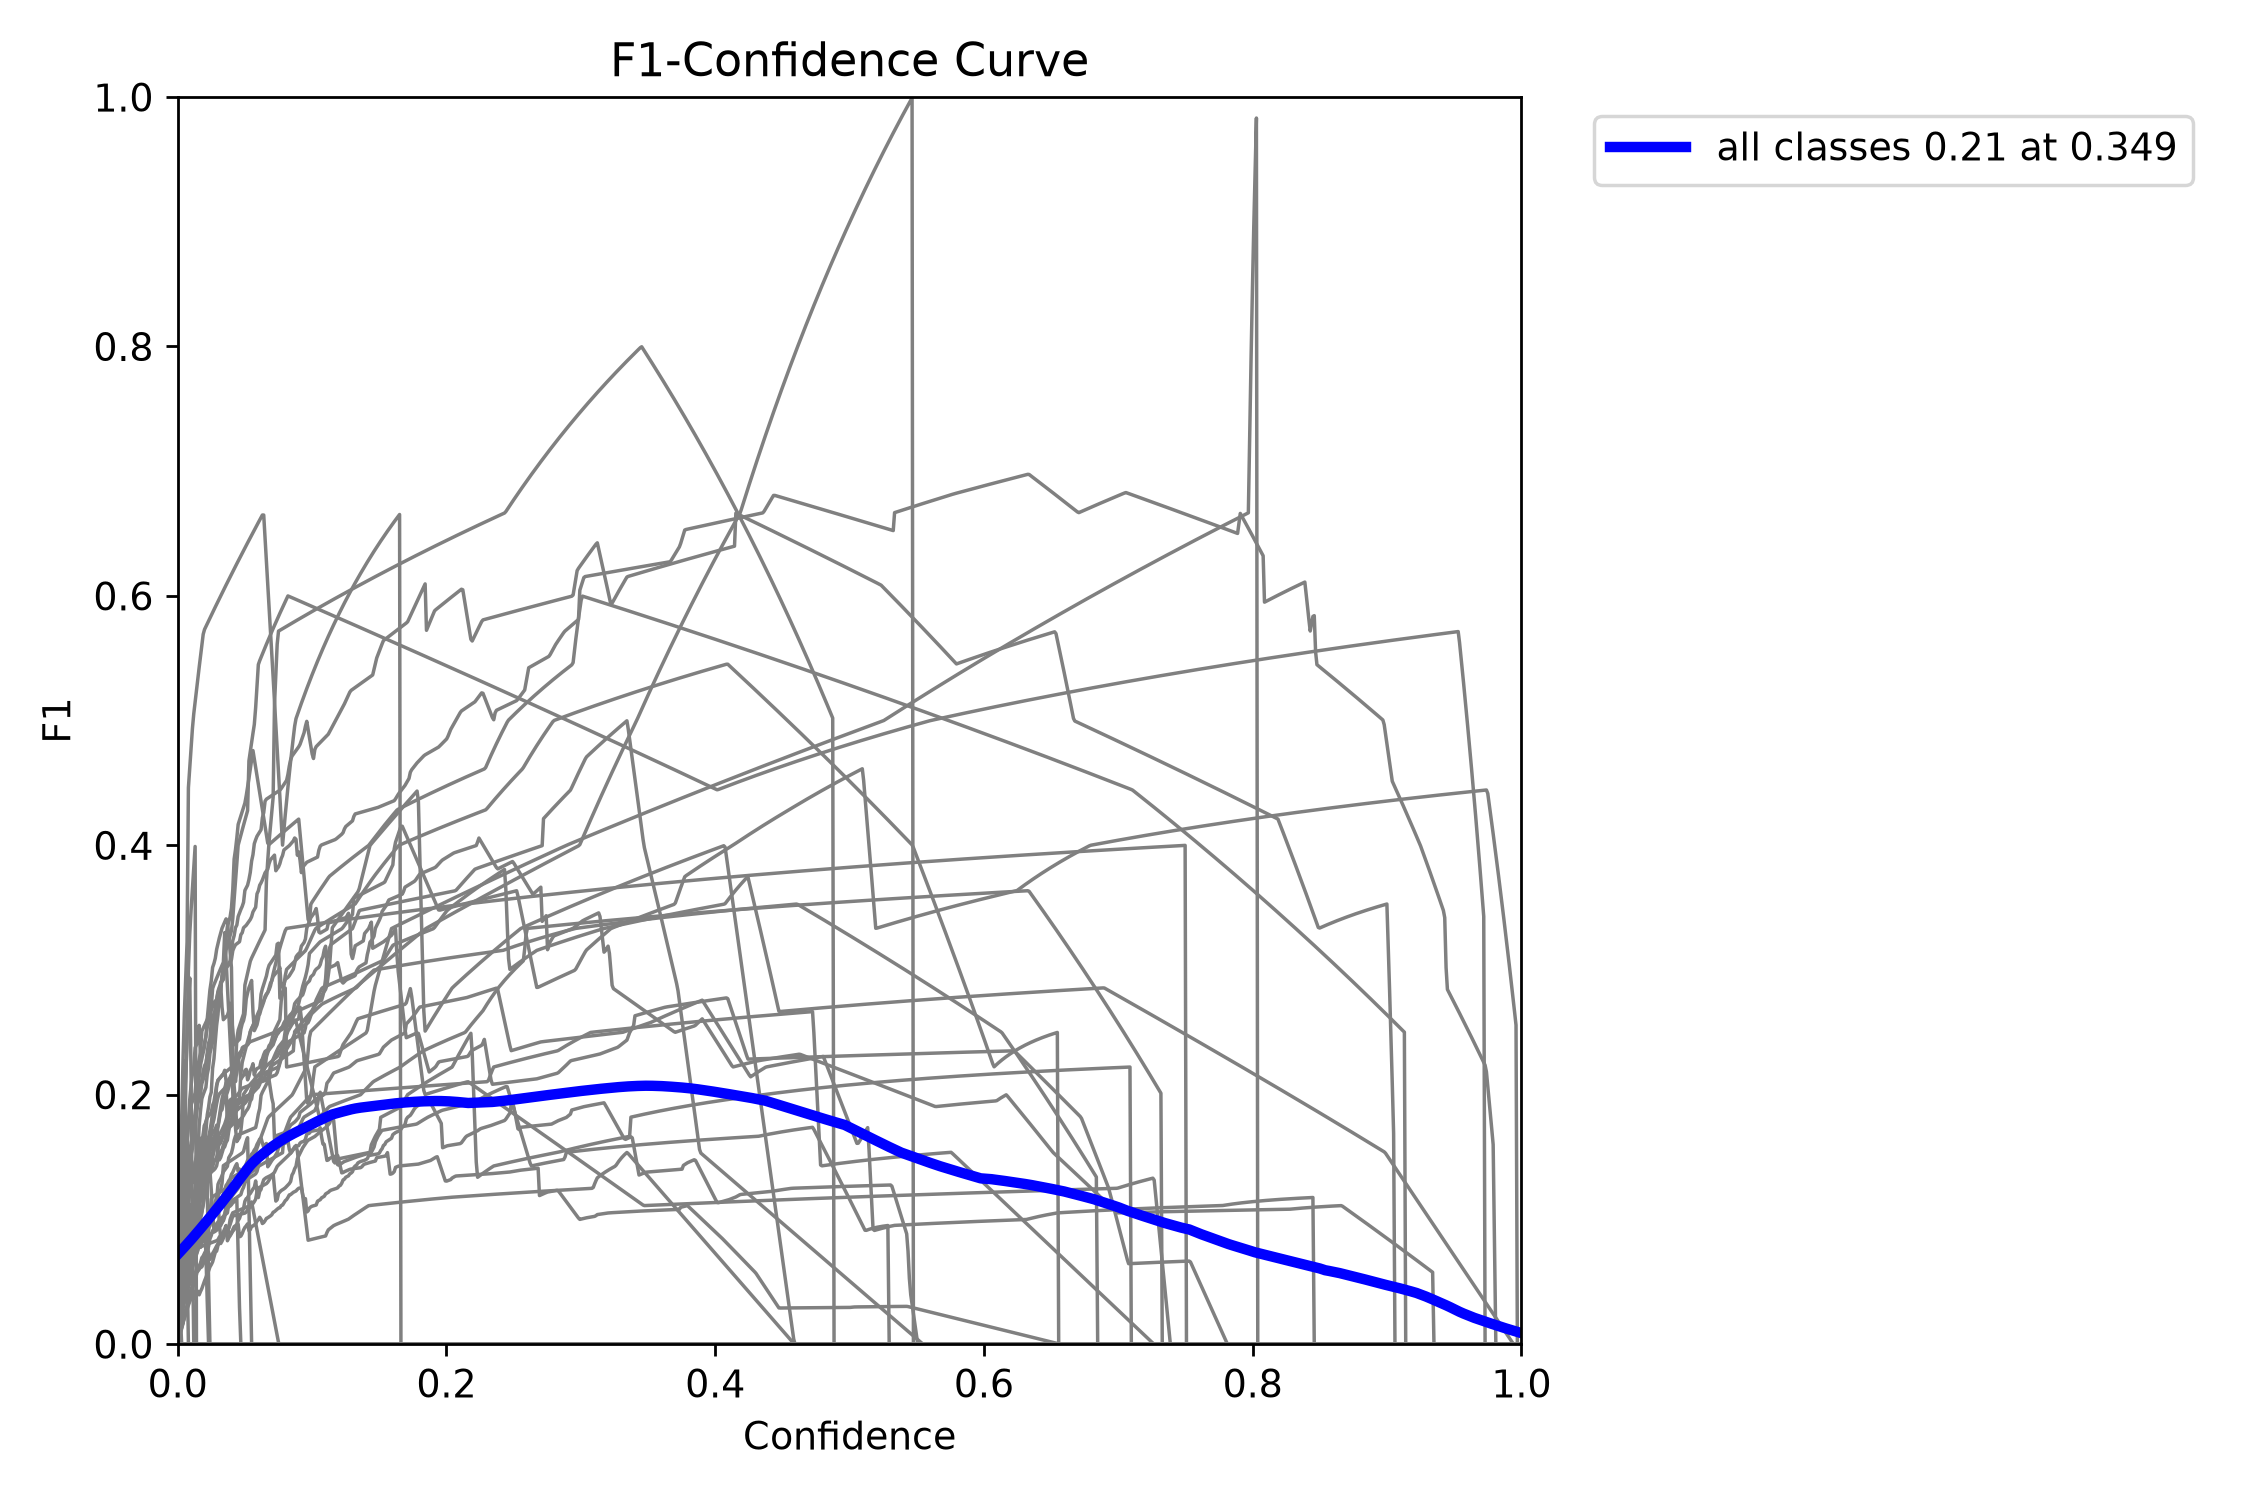

In [8]:
Image(r"../runs/results/train-3/BoxF1_curve.png", width=600)

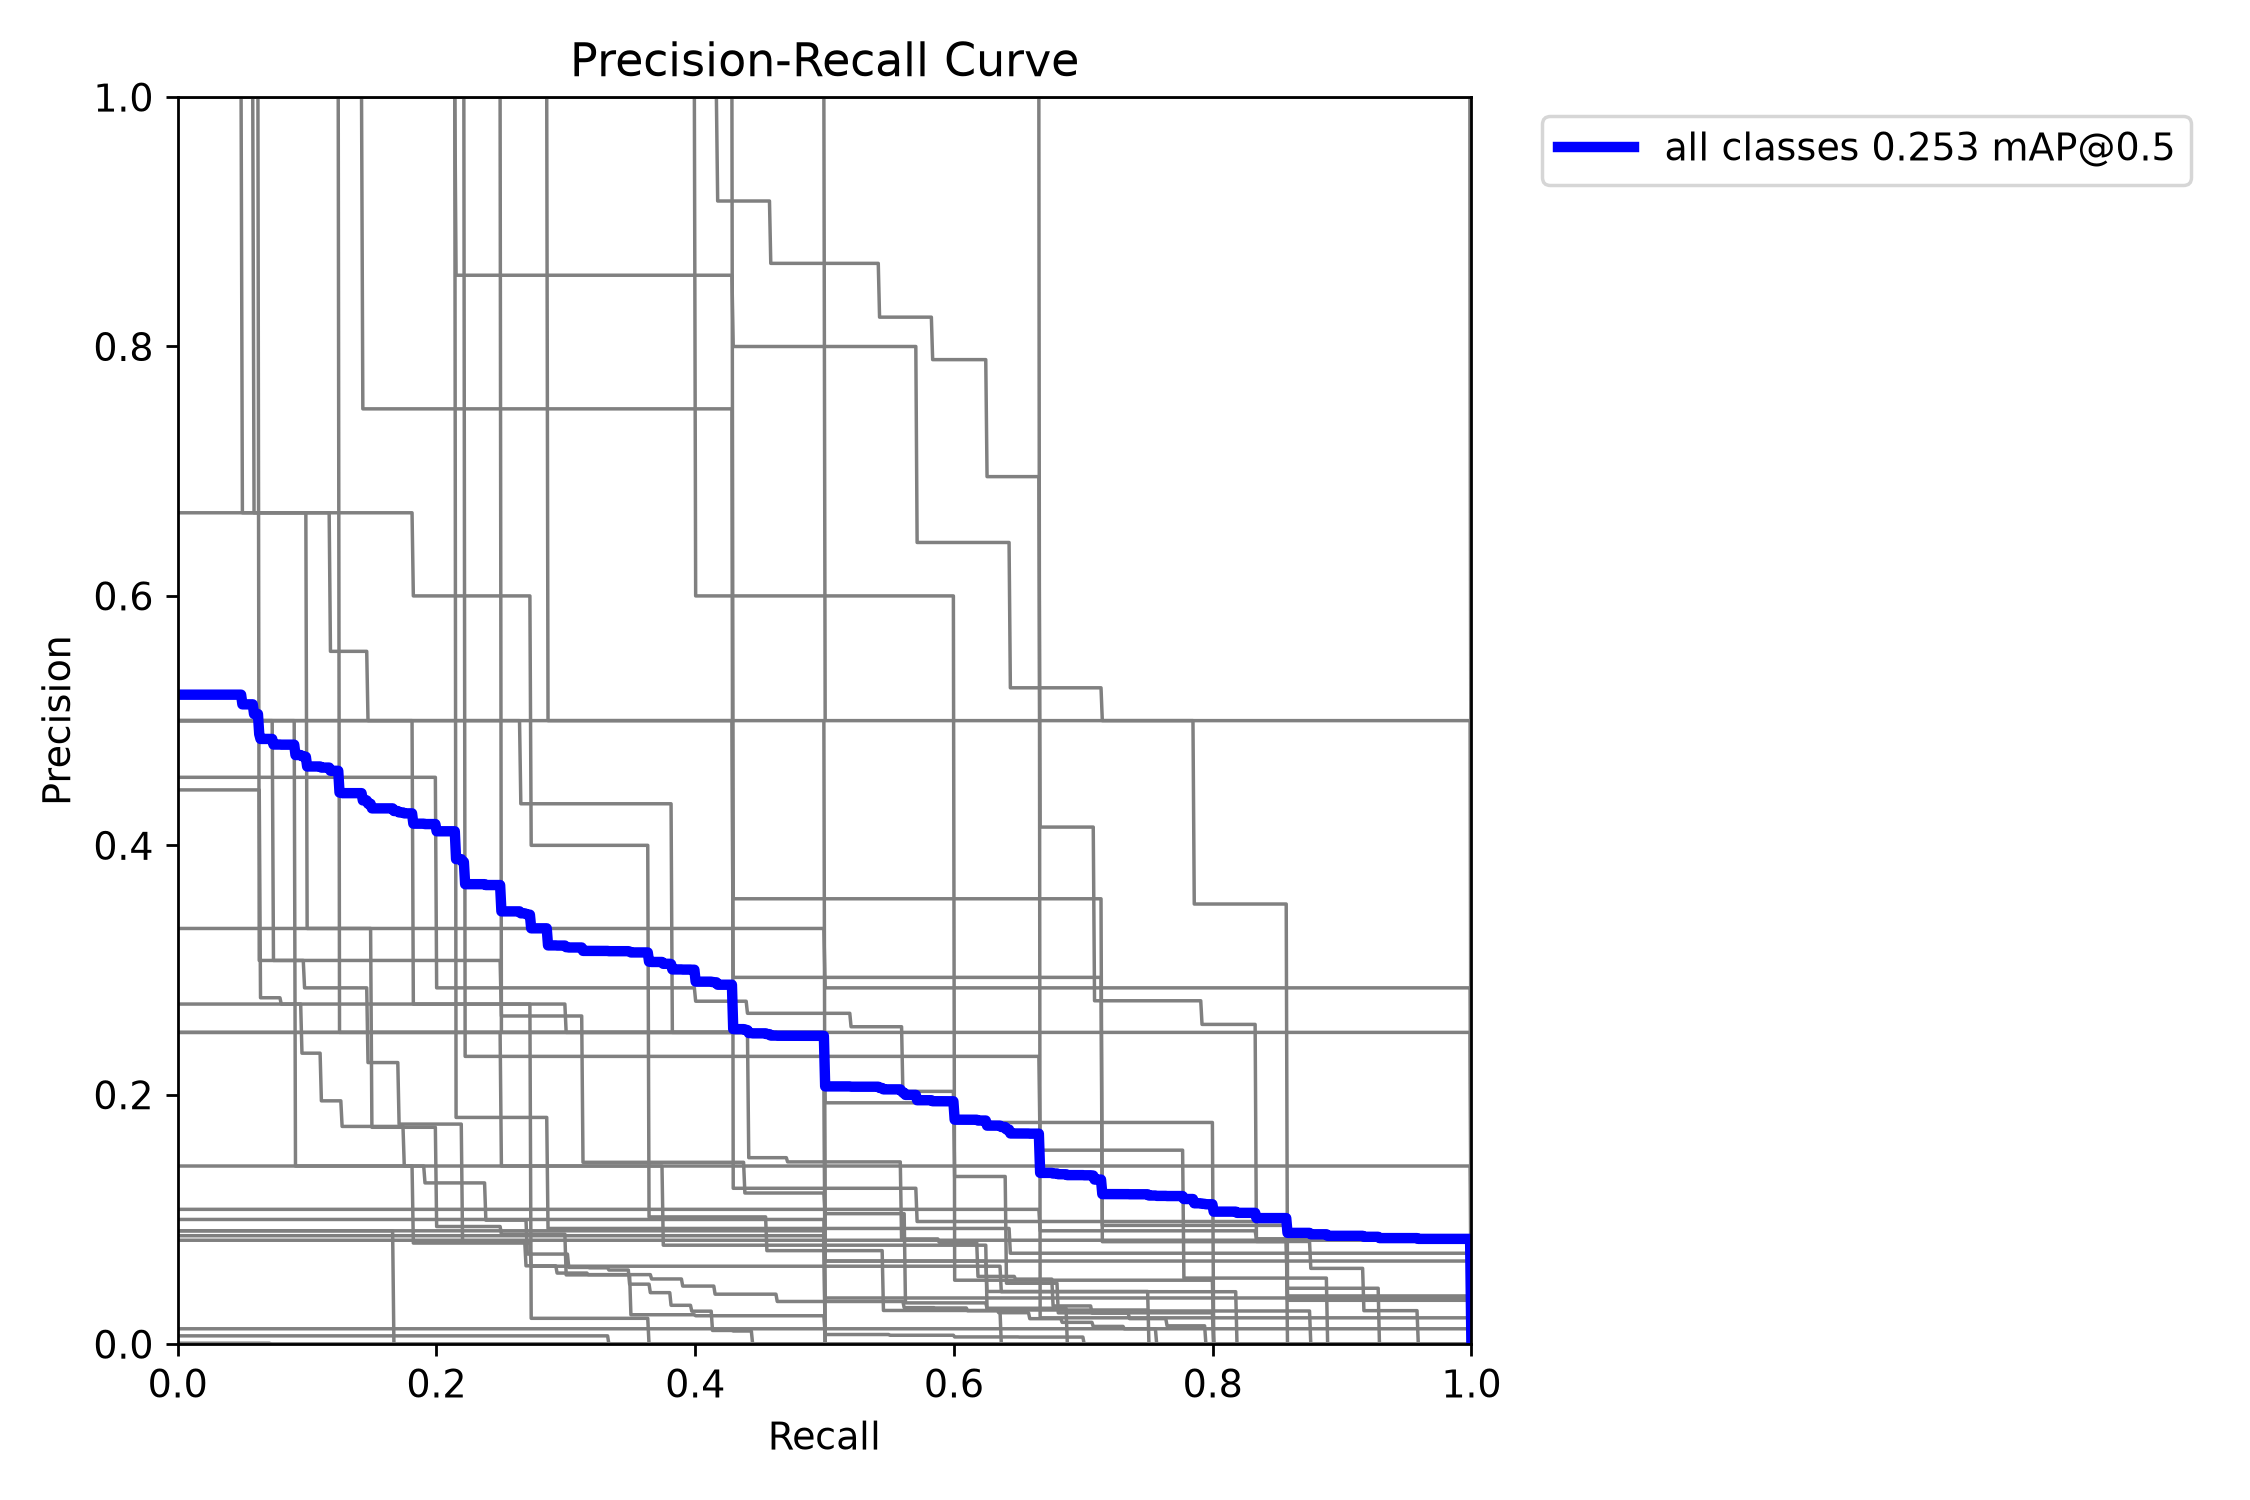

In [9]:
Image(r"../runs/results/train-3/BoxPR_curve.png", width=800)

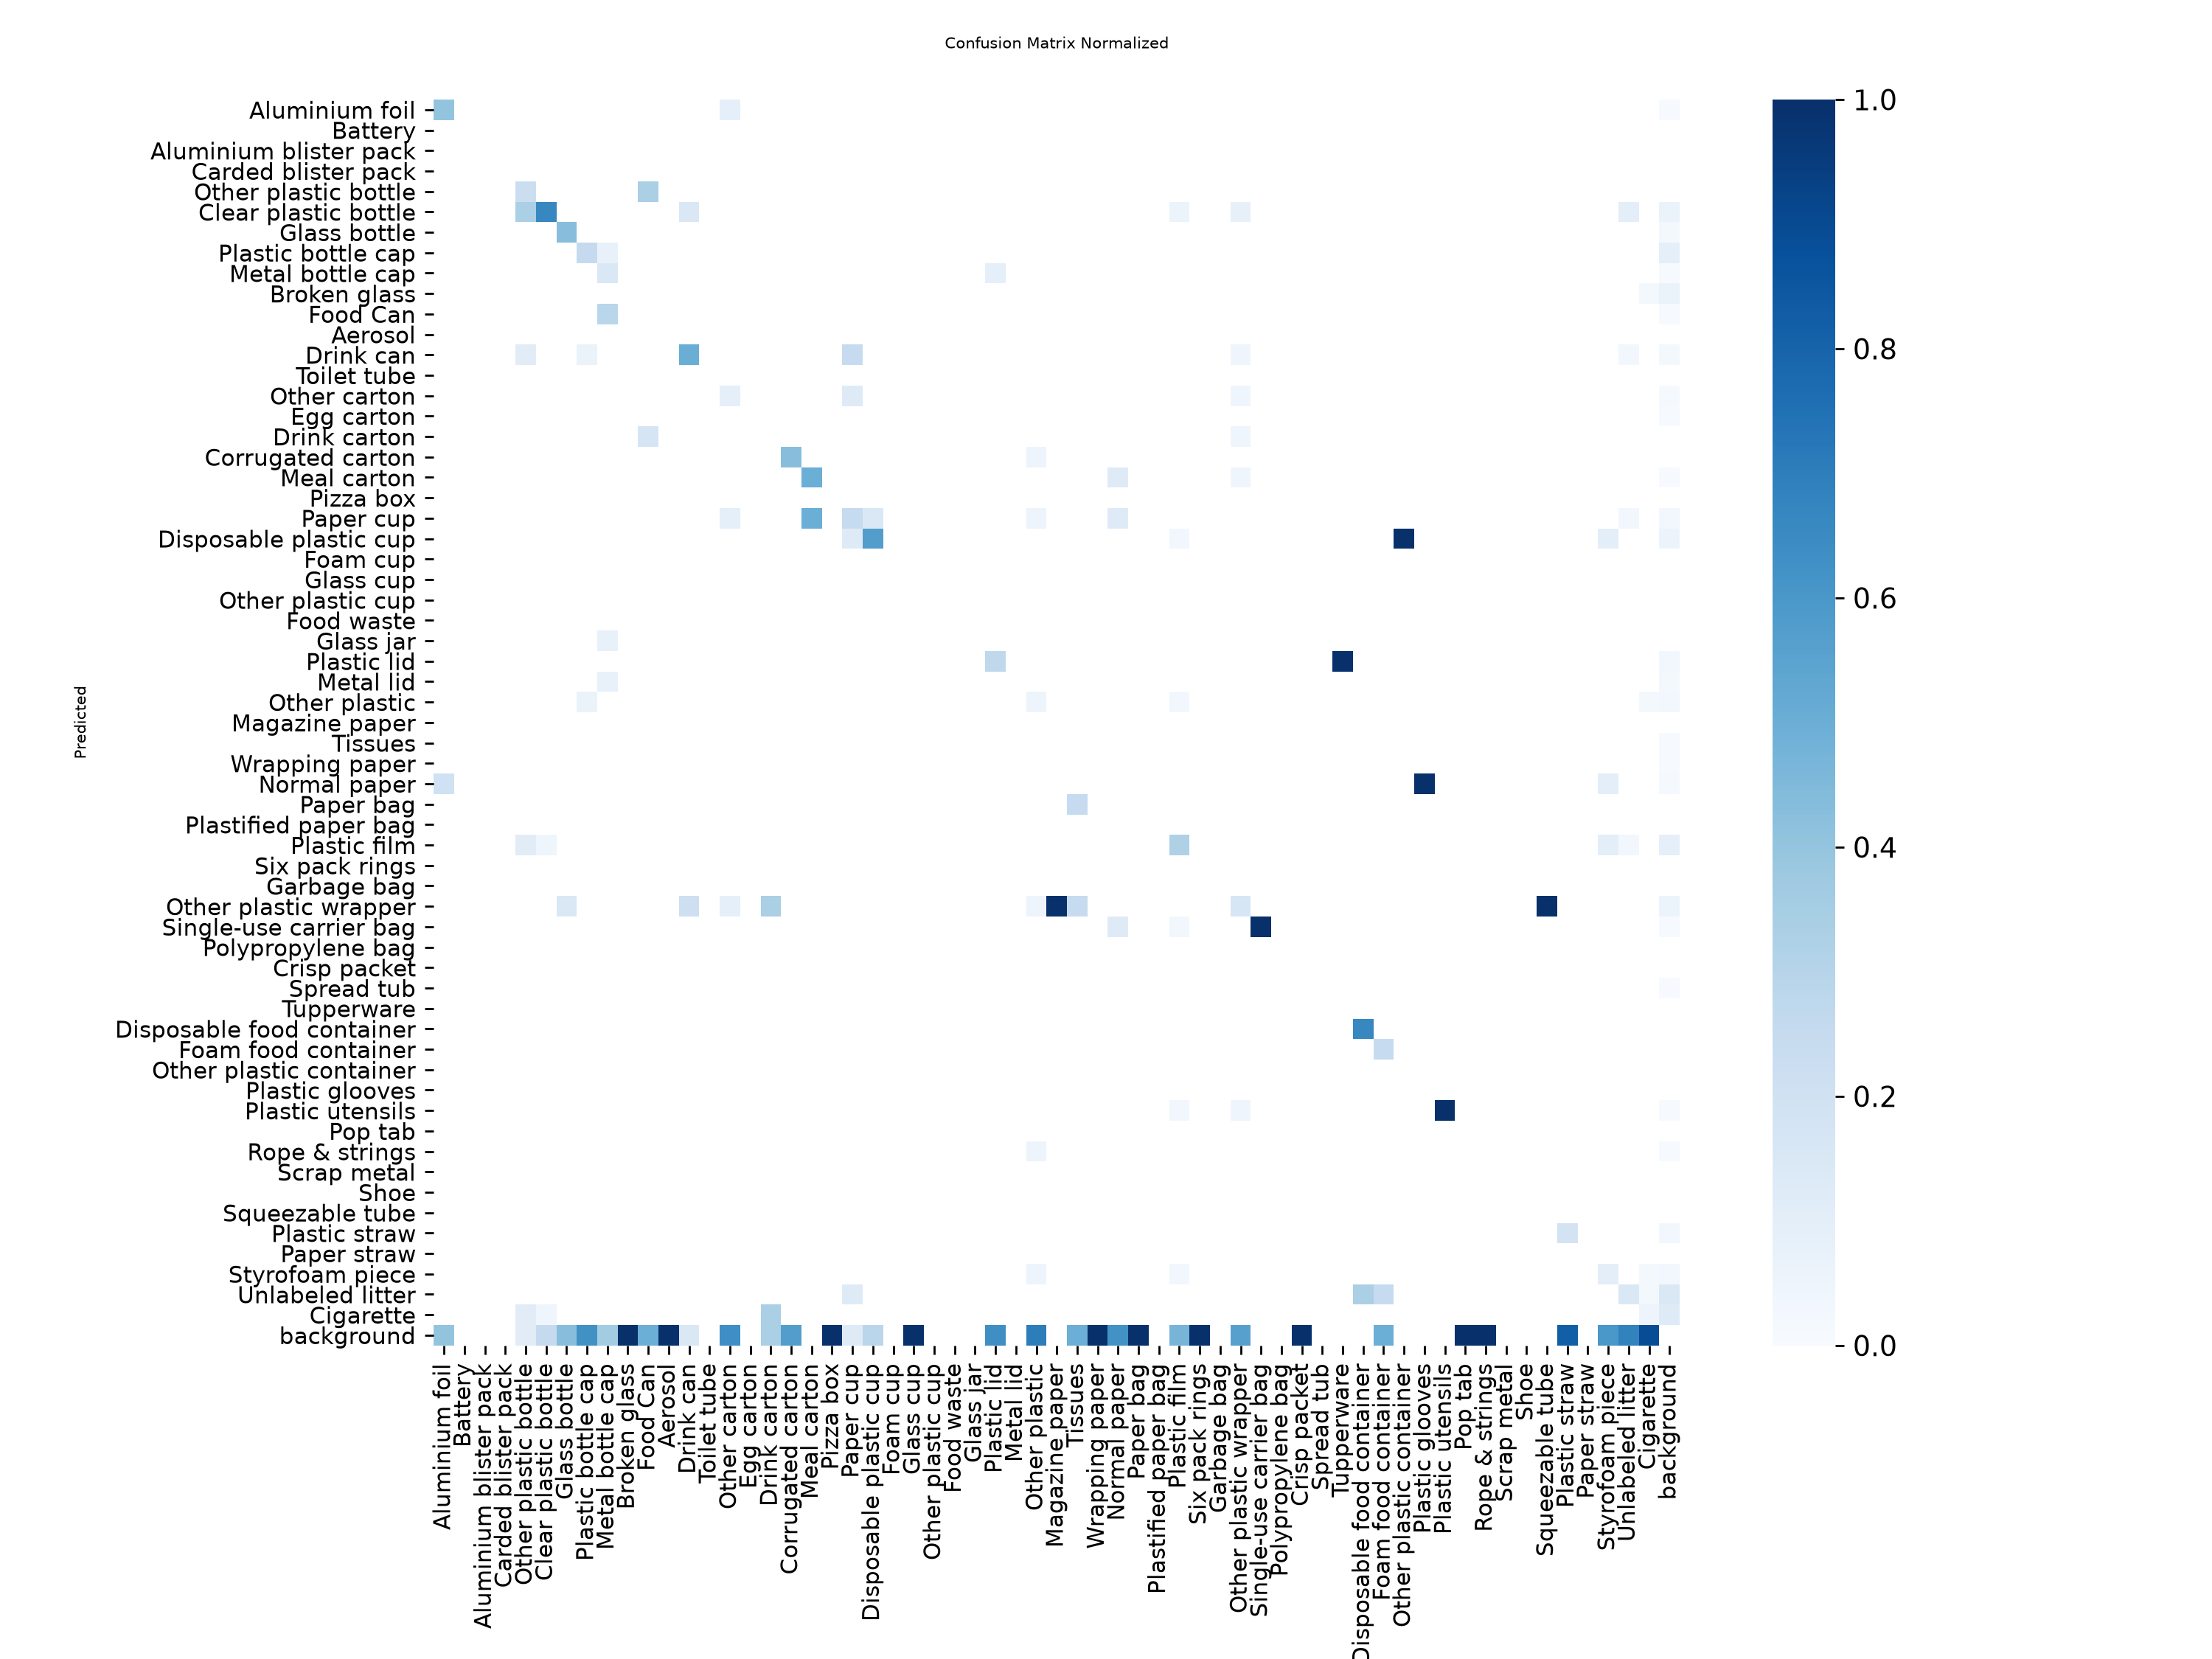

In [11]:
Image(r"../runs/results/train-3/confusion_matrix_normalized.png", width=1200)

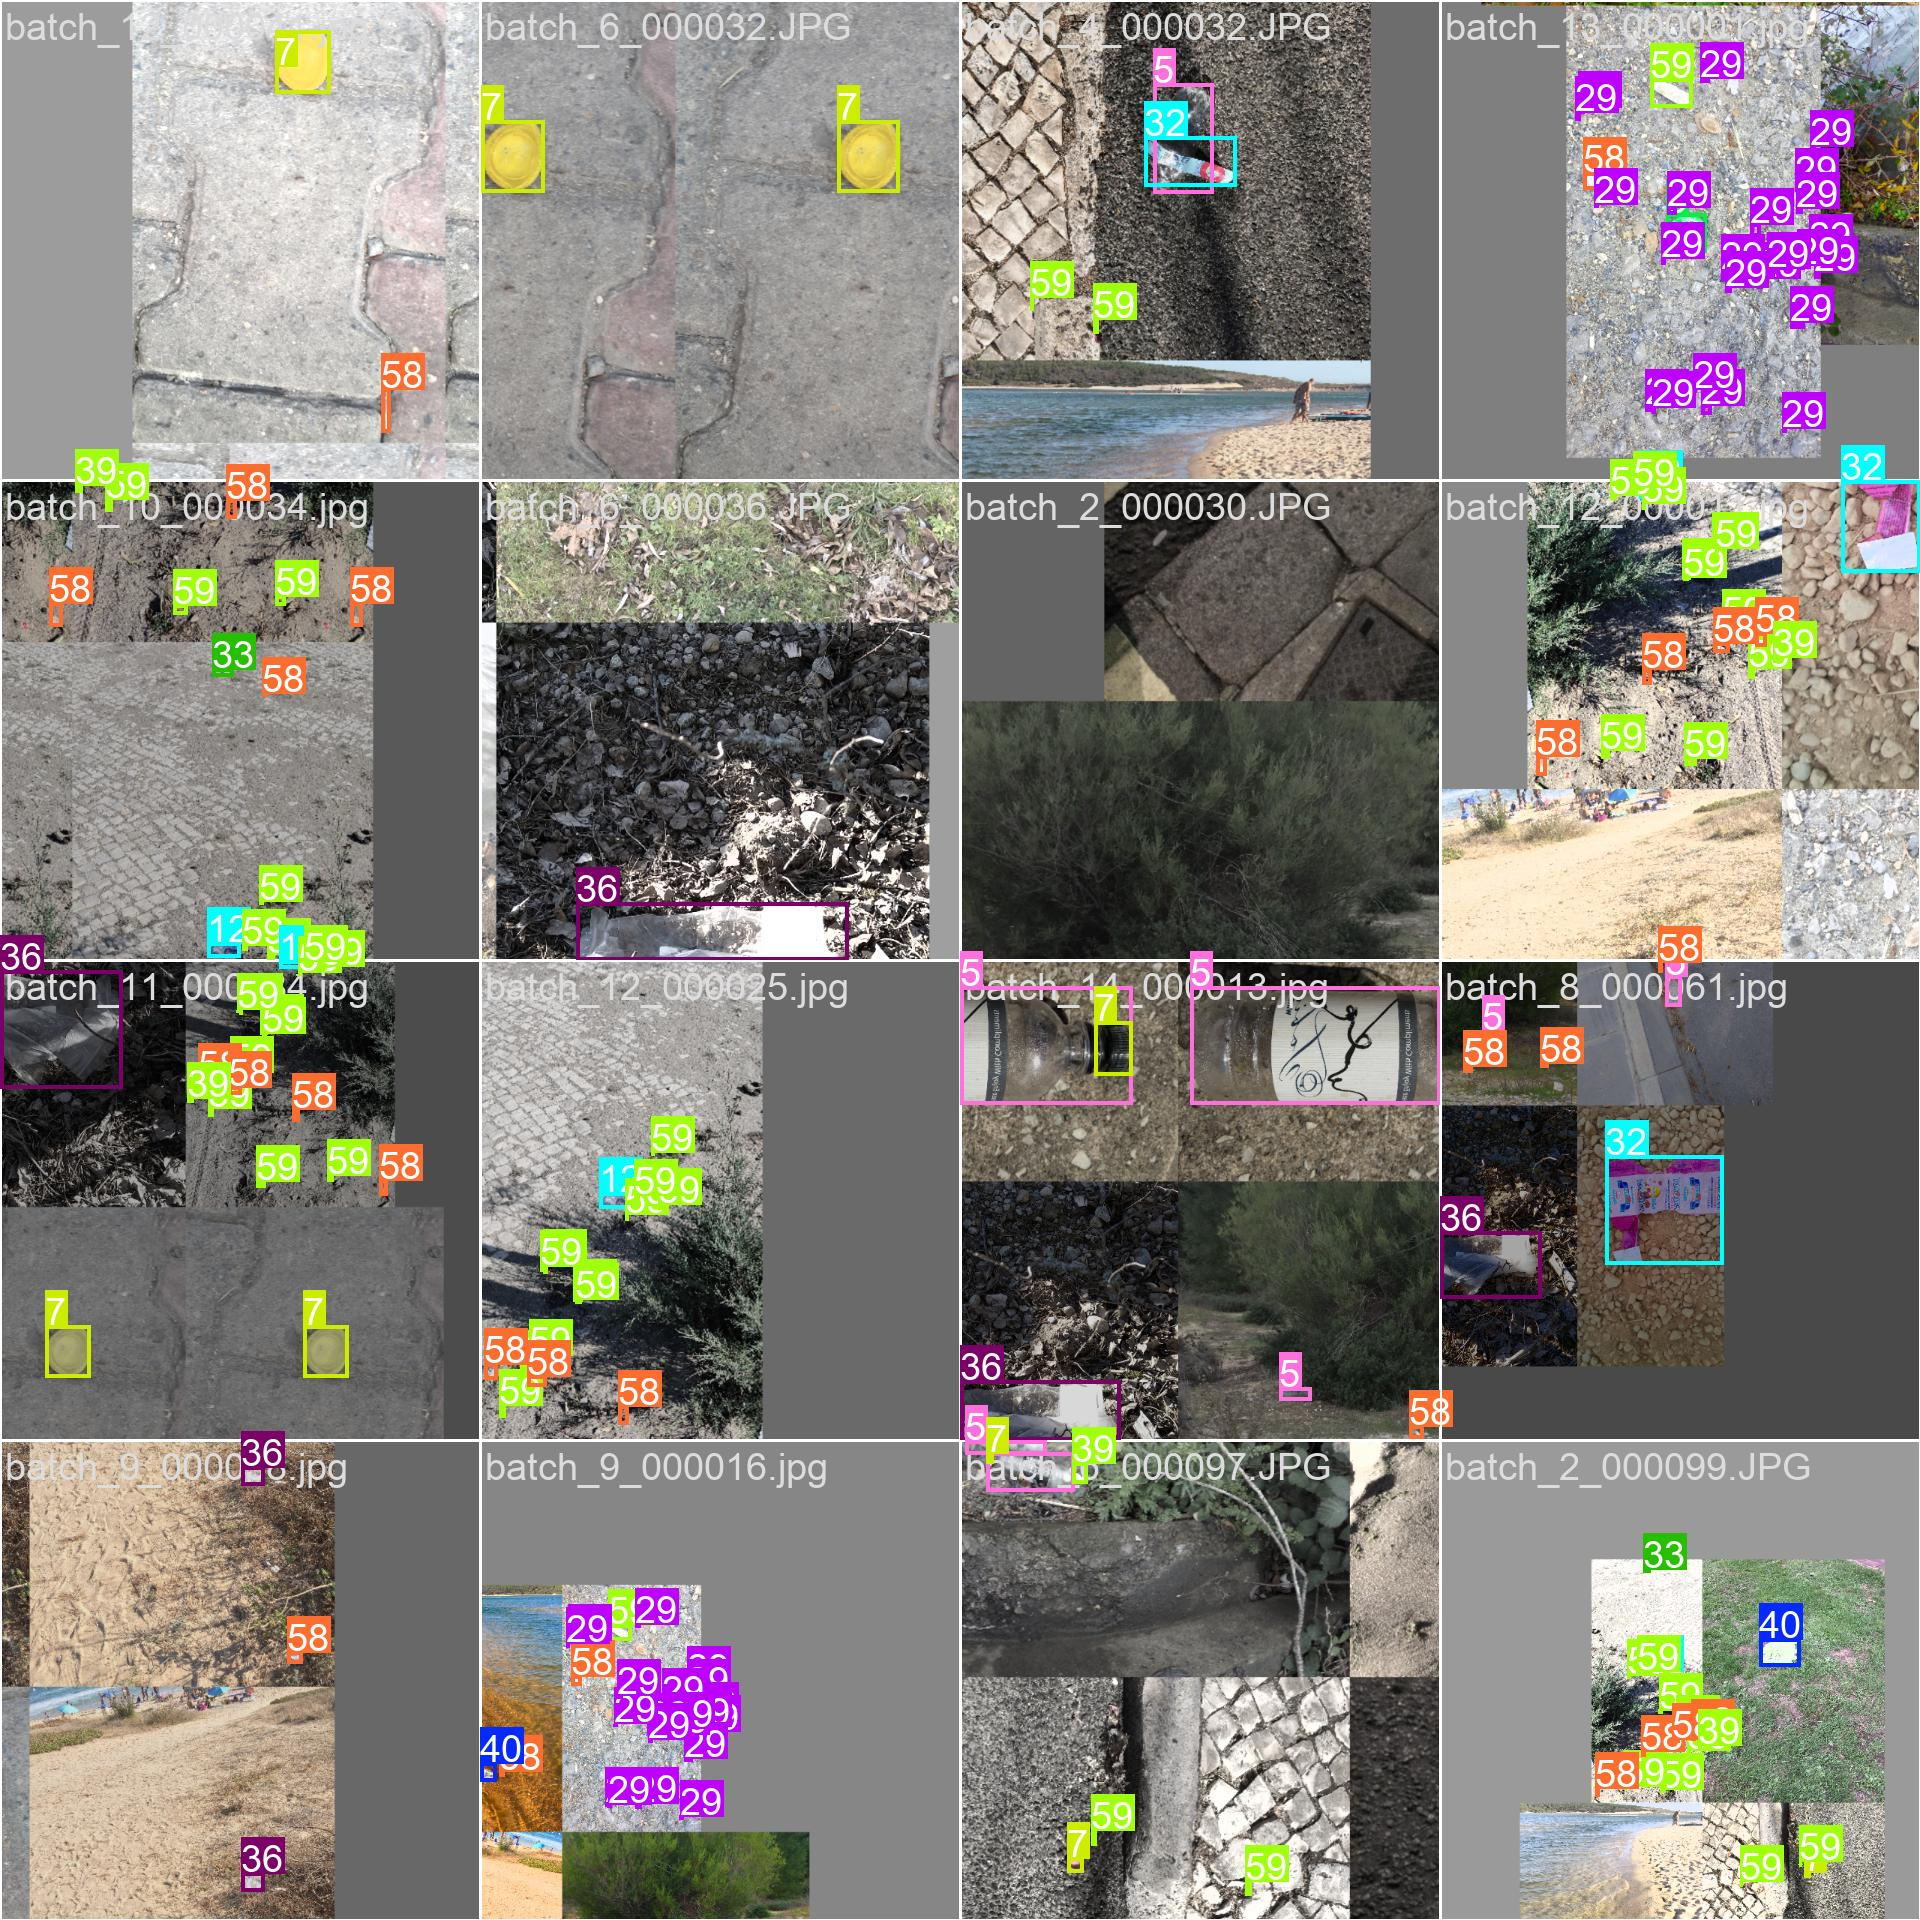

In [12]:
Image(r"../runs/results/train-3/train_batch2.jpg", width=800)

In [13]:
from ultralytics import YOLO

# Load the trained model
model = YOLO(r"../runs/results/train-3/weights/best.pt")

# Validate the model
metrics = model.val(
    data="../dataset_yolo/dataset.yaml"
)

Ultralytics 8.4.91  Python-3.11.9 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 11,148,804 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access  (ping: 0.20.0 ms, read: 848.1386.6 MB/s, size: 1764.6 KB)
val: Scanning D:\Team-Zero-Waste\Waste-Classifcation-YOLOv8-TZW\dataset_yolo\labels\val.cache... 149 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 149/149  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.0it/s 9.8s.5ss
                   all        149        408      0.582      0.204      0.253      0.221
        Aluminium foil          3          5      0.514      0.427      0.525      0.521
  Other plastic bottle          8          9      0.672      0.222       0.35      0.331
  Clear plastic bottle         22         24      0.604      0.667      0.688      0.598
          Glass bottle          7          7      0.686      0.429      

In [19]:
print("mAP@0.5:", metrics.box.map50)
print("mAP@0.5:0.95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

mAP@0.5: 0.25316487978572355
mAP@0.5:0.95: 0.2208999556041056
Precision: 0.5823125978609122
Recall: 0.20428023163587306


In [28]:
import cv2

cap = cv2.VideoCapture(0)

ret, frame = cap.read()

if ret:
    cv2.imwrite("real_time_photo.jpg", frame)
    print("Photo saved")

cap.release()
cv2.destroyAllWindows()

Photo saved


In [29]:
from ultralytics import YOLO

# Load the trained model
model = YOLO(r"../runs/results/train-3/weights/best.pt")

# Run prediction
results = model.predict(
    source="real_time_photo.jpg",
    conf=0.25,
    save=True
)


image 1/1 d:\Team-Zero-Waste\Waste-Classifcation-YOLOv8-TZW\notebook\real_time_photo.jpg: 480x640 1 Drink can, 78.1ms
Speed: 9.3ms preprocess, 78.1ms inference, 20.5ms postprocess per image at shape (1, 3, 480, 640)
Results saved to D:\Team-Zero-Waste\Waste-Classifcation-YOLOv8-TZW\notebook\runs\detect\predict-2


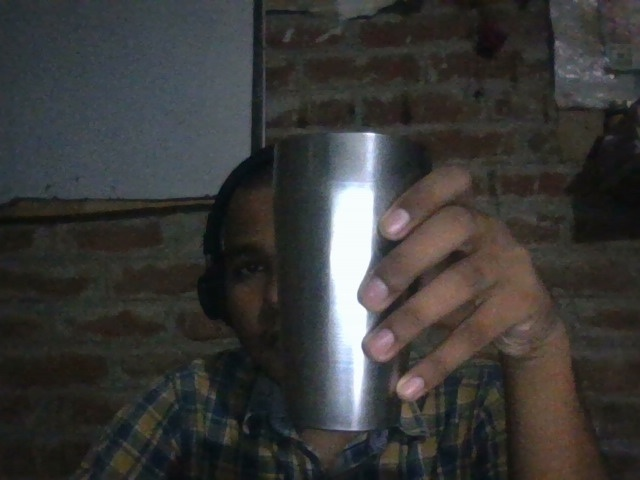

In [23]:
from IPython.display import Image, display

display(Image(r"../runs/results/predict/real_time_photo.jpg"))

In [26]:
import sys
!{sys.executable} -m pip install pickle-mixin

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for pickle-mixin: filename=pickle_mixin-1.0.2-py3-none-any.whl size=6090 sha256=8c4c6dae1aacc9a7e32f4c838a86bfd3c9f96b9a2d22b5dd1aa7829120cb0656
  Stored in directory: c:\users\gunjan\appdata\local\pip\cache\wheels\d0\9c\0d\8709be17c02b72bf04ea60d8ec64fc46a1554c0fb81e048dd6
Successfully built pickle-mixin



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pickle

# Load the trained weights
weights_path = '../runs/results/train-3/weights/best.pt'  
# Load and convert the weights to a pickle file
with open(weights_path, 'rb') as f:
    weights = f.read()
pickle.dump(weights, open('yolov8.pkl', 'wb'))

In [ ]:
from google.colab import files
files.download('yolov8.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>